<a href="https://colab.research.google.com/github/supritha354/dav_lab_program1/blob/main/labprg9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_excel(file_name)
print("Dataset loaded:", file_name)
display(df.head())

Saving student_academic_performance.xlsx to student_academic_performance (1).xlsx
Dataset loaded: student_academic_performance (1).xlsx


,Student_ID,Name,Age,Attendance (%),Maths,Science,English,Total
0,101,Asha,19,90,85,88,80,253
1,102,Rahul,20,85,78,82,75,235
2,103,Priya,19,95,92,90,89,271
3,104,Kiran,21,70,65,72,68,205
4,105,Sneha,20,88,80,85,82,247


In [ ]:
# Create 'Result' column since it is missing in the original dataset
df['Result'] = (df['Total'] >= 240).astype(int)

X = df[['Age', 'Attendance (%)', 'Total']]
y = df['Result']
print("Input features:")
display(X.head())
print("Target:")
display(y.head())

Input features:


,Age,Attendance (%),Total
0,19,90,253
1,20,85,235
2,19,95,271
3,21,70,205
4,20,88,247


Target:


,Result
0,1
1,0
2,1
3,0
4,1


In [ ]:
X_tr , X_test , y_tr , y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify = y)

In [ ]:
tree_clf = DecisionTreeClassifier(max_depth=4 , random_state=42)
tree_clf.fit(X_tr, y_tr)
print("Decision tree madel trained successfully.")

Decision tree madel trained successfully.


In [ ]:
y_pred = tree_clf.predict(X_test)
comparison = pd.DataFrame({
    "Actual Result": y_test.values,
    "Predicted Result": y_pred
})
display(comparison)

,Actual Result,Predicted Result
0,0,0
1,1,1


In [ ]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



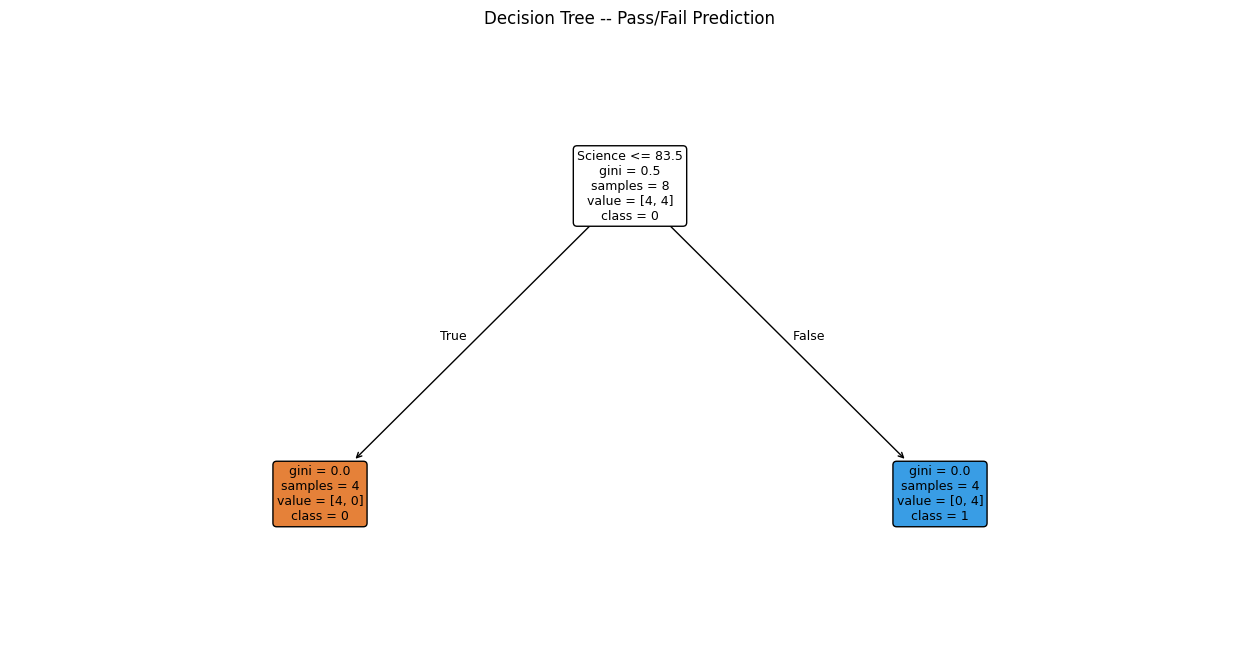

In [ ]:
plt.figure(figsize=(16,8))
plot_tree(
    tree_clf,
    feature_names=X.columns,
    class_names=[str(c) for c in tree_clf.classes_],
    rounded=True,
    filled=True,
    fontsize=9
)
plt.title("Decision Tree -- Pass/Fail Prediction")
plt.show()